# 02 · Extended listing segmentation

## Purpose

This notebook tests whether adding behavioural listing characteristics improves the baseline segmentation. The extended model retains room type and distance from the city centre, then adds availability pattern and minimum-stay regime.

Advertised price and the demand proxy are not used to create the clusters. They are introduced only during profiling so that differences in price and demand can be assessed independently of the variables used to form the segments.

The extended solution is compared directly with the baseline using the same evaluation criteria.

## 1. Imports

The analysis uses the same clustering and validation framework as the baseline so that the comparison is consistent.

In [1]:
from pathlib import Path
from itertools import combinations

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

## 2. Configuration

Candidate solutions from two to eight clusters are evaluated using the same random seed, repeated initialisations, stability checks and minimum cluster-size rule as the baseline analysis.

In [2]:
RANDOM_SEED = 42
K_VALUES = range(2, 9)

N_INIT = 10
STABILITY_RUNS = 5
STABILITY_N_INIT = 3
MAX_ITER = 100

GAMMA = 1.0
MIN_CLUSTER_SHARE = 0.01
SILHOUETTE_SAMPLE_SIZE = 2_000

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "airbnb_cleaned_features.csv"

BASELINE_DIR = PROJECT_ROOT / "outputs" / "clustering" / "baseline"
BASELINE_LABELS_PATH = BASELINE_DIR / "baseline_cluster_labels.csv"
BASELINE_EVALUATION_PATH = BASELINE_DIR / "baseline_cluster_evaluation.csv"
BASELINE_PROFILES_PATH = BASELINE_DIR / "baseline_cluster_profiles.csv"

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "clustering" / "extended"
MODEL_DIR = PROJECT_ROOT / "models" / "clustering"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 3. Load and check the data

The extended segmentation requires room type, distance from the city centre, availability bucket and stay regime. The baseline outputs are also loaded so that the two models can be compared using their observed results.

In [3]:
required_files = [
    DATA_PATH,
    BASELINE_LABELS_PATH,
    BASELINE_EVALUATION_PATH,
    BASELINE_PROFILES_PATH,
]

missing_files = [path for path in required_files if not path.exists()]

if missing_files:
    raise FileNotFoundError(
        "Required files were not found:\n"
        + "\n".join(str(path) for path in missing_files)
    )

df = pd.read_csv(DATA_PATH)
baseline_labels = pd.read_csv(BASELINE_LABELS_PATH)
baseline_evaluation = pd.read_csv(BASELINE_EVALUATION_PATH)
baseline_profiles = pd.read_csv(BASELINE_PROFILES_PATH)

required_columns = {
    "id",
    "room_type",
    "dist_center_km",
    "availability_bucket",
    "stay_regime",
}

missing_columns = sorted(required_columns.difference(df.columns))

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

if df["id"].duplicated().any():
    raise ValueError("Duplicate listing IDs were found. Listing IDs must be unique.")

if baseline_labels["id"].duplicated().any():
    raise ValueError("Duplicate listing IDs were found in the baseline labels.")

baseline_k = baseline_labels["cluster"].nunique()

if baseline_k not in baseline_evaluation["k"].values:
    raise ValueError("The selected baseline value of k was not found in the evaluation table.")

baseline_selected = (
    baseline_evaluation
    .loc[baseline_evaluation["k"].eq(baseline_k)]
    .iloc[0]
)

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Baseline clusters: {baseline_k}")

print("\nMissing values in extended clustering fields:")
display(
    df[
        [
            "id",
            "room_type",
            "dist_center_km",
            "availability_bucket",
            "stay_regime",
        ]
    ]
    .isna()
    .sum()
    .to_frame("missing")
)

Rows: 31,340
Columns: 34
Baseline clusters: 5

Missing values in extended clustering fields:


,missing
id,0
room_type,0
dist_center_km,0
availability_bucket,0
stay_regime,0


## 4. Extended clustering variables

The extended model uses four variables.

- **Room type** captures accommodation format.
- **Distance from the city centre** captures centrality.
- **Availability bucket** captures how extensively a listing is offered during the year.
- **Stay regime** captures the host's minimum-stay pattern.

Price and demand are excluded from the clustering inputs. This allows both measures to remain independent profiling variables when the resulting segments are assessed.

In [4]:
feature_definition = pd.DataFrame(
    {
        "variable": [
            "room_type",
            "dist_center_km",
            "availability_bucket",
            "stay_regime",
        ],
        "data_type": [
            "categorical",
            "numerical",
            "categorical",
            "categorical",
        ],
        "role": [
            "Accommodation format",
            "Location and centrality",
            "Availability pattern",
            "Minimum-stay pattern",
        ],
    }
)

display(feature_definition)

,variable,data_type,role
0,room_type,categorical,Accommodation format
1,dist_center_km,numerical,Location and centrality
2,availability_bucket,categorical,Availability pattern
3,stay_regime,categorical,Minimum-stay pattern


## 5. Prepare the clustering inputs

Distance from the city centre is standardised before clustering. The remaining variables are treated as categorical features.

Rows with missing values in any clustering input are excluded. The number removed is reported before the models are fitted.

In [5]:
cluster_columns = [
    "id",
    "room_type",
    "dist_center_km",
    "availability_bucket",
    "stay_regime",
]

cluster_df = df[cluster_columns].copy()

rows_before = len(cluster_df)
cluster_df = (
    cluster_df
    .dropna(
        subset=[
            "room_type",
            "dist_center_km",
            "availability_bucket",
            "stay_regime",
        ]
    )
    .reset_index(drop=True)
)
rows_after = len(cluster_df)

print(f"Rows before clustering checks: {rows_before:,}")
print(f"Rows retained: {rows_after:,}")
print(f"Rows excluded: {rows_before - rows_after:,}")

if len(cluster_df) < 3:
    raise ValueError("At least three complete observations are required for clustering.")

scaler = StandardScaler()

X_num = scaler.fit_transform(
    cluster_df[["dist_center_km"]].astype(float)
)

X_cat = (
    cluster_df[
        [
            "room_type",
            "availability_bucket",
            "stay_regime",
        ]
    ]
    .astype(str)
    .to_numpy()
)

for column in ["room_type", "availability_bucket", "stay_regime"]:
    print(f"\n{column}:")
    display(cluster_df[column].value_counts().to_frame("listings"))

Rows before clustering checks: 31,340
Rows retained: 31,340
Rows excluded: 0

room_type:


,listings
room_type,
Entire home/apt,16523
Private room,13956
Shared room,861



availability_bucket:


,listings
availability_bucket,
seasonal,7890
half-year,6681
most-of-year,5966
always-on,5638
occasional (<30),5165



stay_regime:


,listings
stay_regime,
short (<=7),25569
long-term (30+),4028
mid (8-29),1743


## 6. K-prototypes functions

K-prototypes combines numerical distance with categorical mismatches. The same implementation is used throughout the segmentation analysis so that differences between the baseline and extended results are driven by the variables rather than a change in clustering method.

In [6]:
def categorical_modes(X_cat, labels, k, rng):
    centres = []

    for cluster_id in range(k):
        members = X_cat[labels == cluster_id]

        if len(members) == 0:
            centres.append(X_cat[rng.integers(0, len(X_cat))].copy())
            continue

        mode_row = []
        for col in range(X_cat.shape[1]):
            values, counts = np.unique(members[:, col], return_counts=True)
            mode_row.append(values[np.argmax(counts)])

        centres.append(mode_row)

    return np.asarray(centres, dtype=object)


def distances_to_prototypes(X_num, X_cat, num_centres, cat_centres, gamma=1.0):
    numeric_distance = (
        (X_num[:, None, :] - num_centres[None, :, :]) ** 2
    ).sum(axis=2)

    categorical_distance = (
        X_cat[:, None, :] != cat_centres[None, :, :]
    ).sum(axis=2)

    return numeric_distance + gamma * categorical_distance


def initialise_prototypes(X_num, X_cat, k, rng):
    indices = rng.choice(len(X_num), size=k, replace=False)
    return X_num[indices].copy(), X_cat[indices].copy()


def fit_single_kprototypes(
    X_num,
    X_cat,
    k,
    gamma=1.0,
    max_iter=100,
    random_state=42,
):
    rng = np.random.default_rng(random_state)
    num_centres, cat_centres = initialise_prototypes(X_num, X_cat, k, rng)

    previous_labels = None

    for iteration in range(max_iter):
        distances = distances_to_prototypes(
            X_num, X_cat, num_centres, cat_centres, gamma
        )
        labels = distances.argmin(axis=1)

        empty_clusters = [
            cluster_id
            for cluster_id in range(k)
            if not np.any(labels == cluster_id)
        ]

        if empty_clusters:
            nearest_distance = distances.min(axis=1)
            replacement_order = np.argsort(nearest_distance)[::-1]

            for cluster_id, row_index in zip(empty_clusters, replacement_order):
                labels[row_index] = cluster_id

        new_num_centres = np.vstack(
            [
                X_num[labels == cluster_id].mean(axis=0)
                for cluster_id in range(k)
            ]
        )

        new_cat_centres = categorical_modes(
            X_cat, labels, k, rng
        )

        if previous_labels is not None and np.array_equal(labels, previous_labels):
            num_centres = new_num_centres
            cat_centres = new_cat_centres
            break

        num_centres = new_num_centres
        cat_centres = new_cat_centres
        previous_labels = labels.copy()

    final_distances = distances_to_prototypes(
        X_num, X_cat, num_centres, cat_centres, gamma
    )

    labels = final_distances.argmin(axis=1)
    cost = final_distances[np.arange(len(labels)), labels].sum()

    return {
        "labels": labels,
        "num_centres": num_centres,
        "cat_centres": cat_centres,
        "cost": float(cost),
        "iterations": iteration + 1,
        "gamma": gamma,
    }


def fit_kprototypes(
    X_num,
    X_cat,
    k,
    gamma=1.0,
    n_init=10,
    max_iter=100,
    random_state=42,
):
    best_model = None

    for run in range(n_init):
        seed = random_state + run

        model = fit_single_kprototypes(
            X_num=X_num,
            X_cat=X_cat,
            k=k,
            gamma=gamma,
            max_iter=max_iter,
            random_state=seed,
        )

        if best_model is None or model["cost"] < best_model["cost"]:
            best_model = model

    return best_model


def mixed_distance_matrix(X_num, X_cat, gamma=1.0):
    numeric = (
        (X_num[:, None, :] - X_num[None, :, :]) ** 2
    ).sum(axis=2)

    categorical = (
        X_cat[:, None, :] != X_cat[None, :, :]
    ).sum(axis=2)

    return numeric + gamma * categorical


def clustering_stability(
    X_num,
    X_cat,
    k,
    gamma,
    runs,
    n_init,
    max_iter,
    random_state,
):
    label_sets = []

    for run in range(runs):
        model = fit_kprototypes(
            X_num=X_num,
            X_cat=X_cat,
            k=k,
            gamma=gamma,
            n_init=n_init,
            max_iter=max_iter,
            random_state=random_state + (run * 100),
        )

        label_sets.append(model["labels"])

    pair_scores = [
        adjusted_rand_score(label_sets[i], label_sets[j])
        for i, j in combinations(range(len(label_sets)), 2)
    ]

    return float(np.mean(pair_scores)) if pair_scores else np.nan

## 7. Compare candidate numbers of clusters

The extended solutions are assessed using the same criteria as the baseline: within-cluster cost, silhouette score, repeated-run stability and cluster size.

Silhouette is calculated from a fixed random sample when the dataset is large. The same observations are used for every candidate value of `k`.

In [7]:
candidate_k = [k for k in K_VALUES if k < len(cluster_df)]

rng = np.random.default_rng(RANDOM_SEED)
silhouette_n = min(SILHOUETTE_SAMPLE_SIZE, len(cluster_df))

silhouette_index = np.sort(
    rng.choice(
        len(cluster_df),
        size=silhouette_n,
        replace=False,
    )
)

X_num_sil = X_num[silhouette_index]
X_cat_sil = X_cat[silhouette_index]

D_silhouette = mixed_distance_matrix(
    X_num_sil,
    X_cat_sil,
    gamma=GAMMA,
)

results = []
models = {}

for k in candidate_k:
    model = fit_kprototypes(
        X_num=X_num,
        X_cat=X_cat,
        k=k,
        gamma=GAMMA,
        n_init=N_INIT,
        max_iter=MAX_ITER,
        random_state=RANDOM_SEED,
    )

    labels = model["labels"]
    counts = pd.Series(labels).value_counts()

    sample_labels = labels[silhouette_index]
    sample_counts = pd.Series(sample_labels).value_counts()

    silhouette = np.nan

    if (
        len(np.unique(sample_labels)) > 1
        and sample_counts.min() > 1
    ):
        silhouette = silhouette_score(
            D_silhouette,
            sample_labels,
            metric="precomputed",
        )

    stability = clustering_stability(
        X_num=X_num,
        X_cat=X_cat,
        k=k,
        gamma=GAMMA,
        runs=STABILITY_RUNS,
        n_init=STABILITY_N_INIT,
        max_iter=MAX_ITER,
        random_state=RANDOM_SEED,
    )

    results.append(
        {
            "k": k,
            "cost": model["cost"],
            "silhouette": silhouette,
            "stability_ari": stability,
            "smallest_cluster_n": int(counts.min()),
            "largest_cluster_n": int(counts.max()),
            "smallest_cluster_share": counts.min() / len(labels),
        }
    )

    models[k] = model

results_df = pd.DataFrame(results)
display(results_df.round(4))

,k,cost,silhouette,stability_ari,smallest_cluster_n,largest_cluster_n,smallest_cluster_share
0,2,"52,250.232",0.406,0.883,13604,17736,0.434
1,3,"44,005.485",0.313,0.660,5086,14047,0.162
2,4,"39,438.917",0.302,0.503,4756,9815,0.152
3,5,"35,806.508",0.260,0.355,3777,9326,0.120
4,6,"33,732.422",0.242,0.322,3092,8442,0.099
5,7,"30,531.924",0.240,0.348,1944,6660,0.062
6,8,"28,562.963",0.251,0.302,2320,5147,0.074


## 8. Evaluation charts

The three evaluation charts show whether additional clusters improve separation and whether the resulting memberships remain stable across repeated fits.

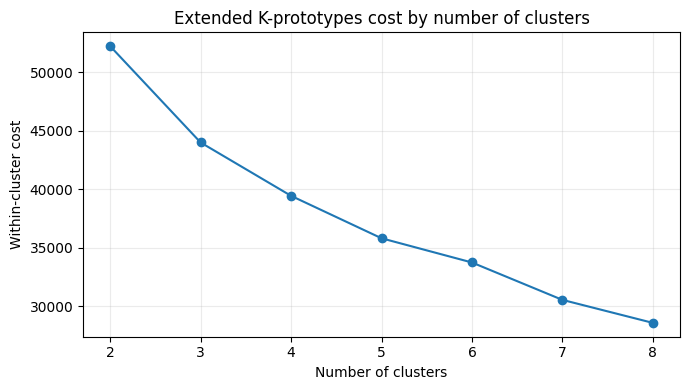

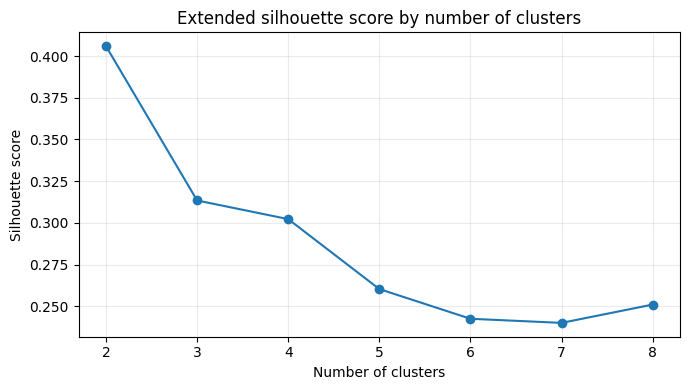

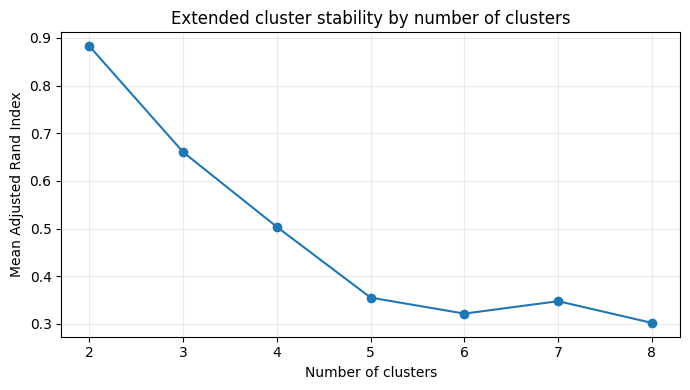

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(results_df["k"], results_df["cost"], marker="o")
ax.set_title("Extended K-prototypes cost by number of clusters")
ax.set_xlabel("Number of clusters")
ax.set_ylabel("Within-cluster cost")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(results_df["k"], results_df["silhouette"], marker="o")
ax.set_title("Extended silhouette score by number of clusters")
ax.set_xlabel("Number of clusters")
ax.set_ylabel("Silhouette score")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(results_df["k"], results_df["stability_ari"], marker="o")
ax.set_title("Extended cluster stability by number of clusters")
ax.set_xlabel("Number of clusters")
ax.set_ylabel("Mean Adjusted Rand Index")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Select the extended solution

Solutions containing very small clusters are excluded where possible. Among the remaining candidates, silhouette is used as the main measure of separation and stability is used as a secondary check.

The selected value of `k` is then profiled before the extended model is compared with the baseline.

In [9]:
minimum_cluster_n = max(
    2,
    int(np.ceil(MIN_CLUSTER_SHARE * len(cluster_df))),
)

eligible = results_df[
    results_df["smallest_cluster_n"] >= minimum_cluster_n
].copy()

if eligible.empty:
    eligible = results_df.copy()

with_silhouette = eligible.dropna(subset=["silhouette"])

if not with_silhouette.empty:
    selected_row = (
        with_silhouette
        .sort_values(
            ["silhouette", "stability_ari"],
            ascending=[False, False],
        )
        .iloc[0]
    )
else:
    selected_row = (
        eligible
        .sort_values("stability_ari", ascending=False)
        .iloc[0]
    )

SELECTED_K = int(selected_row["k"])
selected_model = models[SELECTED_K]

cluster_df["cluster"] = selected_model["labels"]

print(f"Selected extended solution: k = {SELECTED_K}")
print(f"Minimum cluster size required: {minimum_cluster_n:,}")
display(selected_row.to_frame("value"))

Selected extended solution: k = 2
Minimum cluster size required: 314


,value
k,2.000
cost,"52,250.232"
silhouette,0.406
stability_ari,0.883
smallest_cluster_n,"13,604.000"
largest_cluster_n,"17,736.000"
smallest_cluster_share,0.434


## 10. Inspect the extended prototypes

The numerical prototype is converted back to kilometres. The categorical prototypes show the room type, availability pattern and stay regime associated with each cluster centre.

In [10]:
prototype_distance_km = scaler.inverse_transform(
    selected_model["num_centres"]
)[:, 0]

prototype_table = pd.DataFrame(
    {
        "cluster": range(SELECTED_K),
        "prototype_room_type": selected_model["cat_centres"][:, 0],
        "prototype_availability_bucket": selected_model["cat_centres"][:, 1],
        "prototype_stay_regime": selected_model["cat_centres"][:, 2],
        "prototype_distance_km": prototype_distance_km,
    }
)

prototype_table["prototype_distance_km"] = (
    prototype_table["prototype_distance_km"].round(2)
)

display(prototype_table)

,cluster,prototype_room_type,prototype_availability_bucket,prototype_stay_regime,prototype_distance_km
0,0,Private room,seasonal,short (<=7),11.400
1,1,Entire home/apt,half-year,short (<=7),4.430


## 11. Profile the extended segments

The cluster labels are joined back to the wider dataset for interpretation. Price and demand are introduced only after the clusters have been formed.

Demand is summarised only for records where the reliability flag is valid.

In [11]:
label_map = cluster_df[["id", "cluster"]].copy()

profile_df = df.merge(
    label_map,
    on="id",
    how="inner",
    validate="one_to_one",
)

numeric_profile_candidates = [
    "price",
    "availability_365",
    "minimum_nights",
    "calculated_host_listings_count",
    "dist_center_km",
    "reviews_per_month",
]

numeric_profiles = [
    column
    for column in numeric_profile_candidates
    if column in profile_df.columns
]

profile_summary = (
    profile_df
    .groupby("cluster")[numeric_profiles]
    .median()
    .add_prefix("median_")
)

profile_summary.insert(
    0,
    "listings",
    profile_df.groupby("cluster").size(),
)

if {"demand_rate_year", "demand_reliable"}.issubset(profile_df.columns):
    reliable_demand = profile_df.loc[
        profile_df["demand_reliable"].eq(1)
        & profile_df["demand_rate_year"].notna()
    ]

    demand_summary = (
        reliable_demand
        .groupby("cluster")["demand_rate_year"]
        .agg(
            reliable_demand_n="size",
            median_demand_rate_year="median",
        )
    )

    profile_summary = profile_summary.join(
        demand_summary,
        how="left",
    )

display(profile_summary.round(2))

,listings,median_price,median_availability_365,median_minimum_nights,median_calculated_host_listings_count,median_dist_center_km,median_reviews_per_month,reliable_demand_n,median_demand_rate_year
cluster,,,,,,,,,
0,13604,73.000,137.000,2.000,1.000,10.270,1.000,11897,27.290
1,17736,155.000,179.000,3.000,1.000,4.280,0.770,14278,17.030


In [12]:
def mode_or_nan(series):
    mode = series.dropna().mode()
    return mode.iloc[0] if len(mode) else np.nan


categorical_profile_candidates = [
    "room_type",
    "availability_bucket",
    "stay_regime",
    "neighbourhood_group",
    "nbhd_price_tier",
    "is_luxury_v2",
]

categorical_profiles = [
    column
    for column in categorical_profile_candidates
    if column in profile_df.columns
]

if categorical_profiles:
    categorical_summary = (
        profile_df
        .groupby("cluster")[categorical_profiles]
        .agg(mode_or_nan)
    )

    display(categorical_summary)

,room_type,availability_bucket,stay_regime,neighbourhood_group,nbhd_price_tier,is_luxury_v2
cluster,,,,,,
0,Private room,seasonal,short (<=7),Brooklyn,mid,0
1,Entire home/apt,half-year,short (<=7),Manhattan,top,0


## 12. Segment composition and outcome profiles

Composition charts show how the categorical variables are distributed within each segment. Price and demand charts are descriptive outcomes rather than clustering inputs.

room_type,Entire home/apt,Private room,Shared room
cluster,,,
0,28.200,68.600,3.100
1,71.500,26.100,2.500


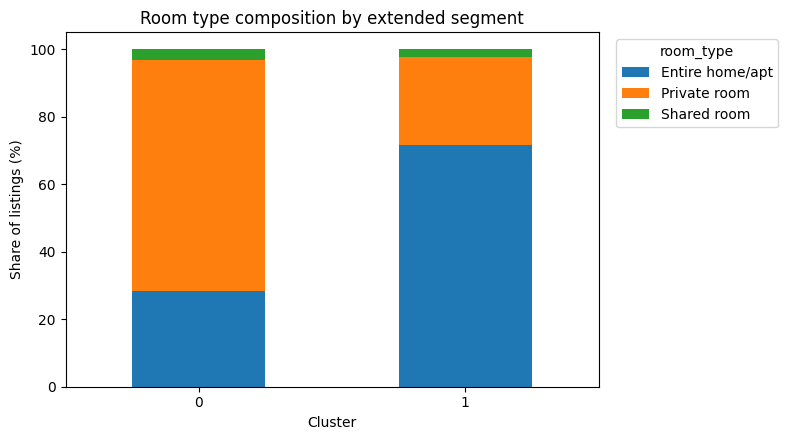

availability_bucket,always-on,half-year,most-of-year,occasional (<30),seasonal
cluster,,,,,
0,18.800,15.700,17.600,12.500,35.300
1,17.300,25.600,20.200,19.500,17.400


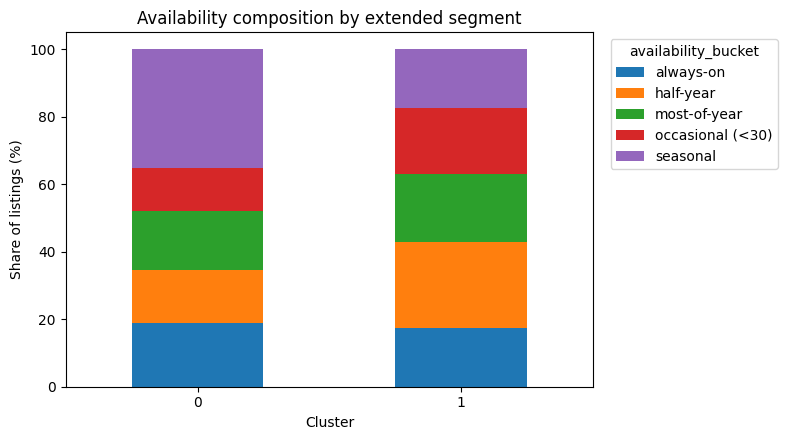

stay_regime,long-term (30+),mid (8-29),short (<=7)
cluster,,,
0,7.300,4.400,88.400
1,17.100,6.500,76.400


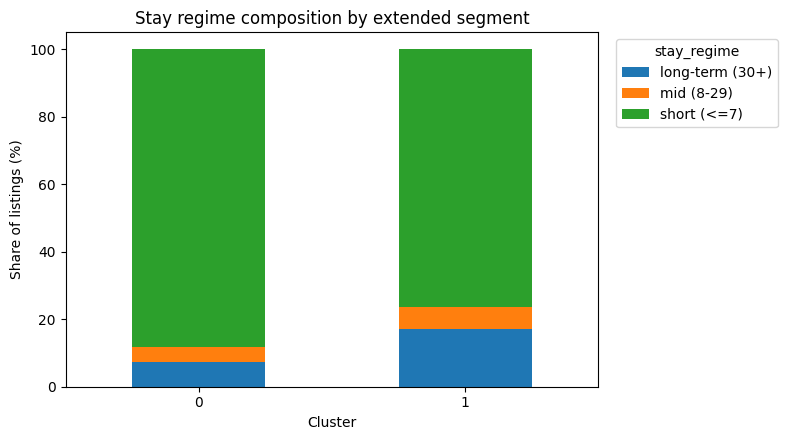

In [13]:
def composition_table(data, column):
    return (
        pd.crosstab(
            data["cluster"],
            data[column],
            normalize="index",
        )
        .mul(100)
        .sort_index()
    )


for column, title in [
    ("room_type", "Room type composition by extended segment"),
    ("availability_bucket", "Availability composition by extended segment"),
    ("stay_regime", "Stay regime composition by extended segment"),
]:
    composition = composition_table(profile_df, column)
    display(composition.round(1))

    fig, ax = plt.subplots(figsize=(8, 4.5))
    composition.plot(
        kind="bar",
        stacked=True,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Share of listings (%)")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title=column, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

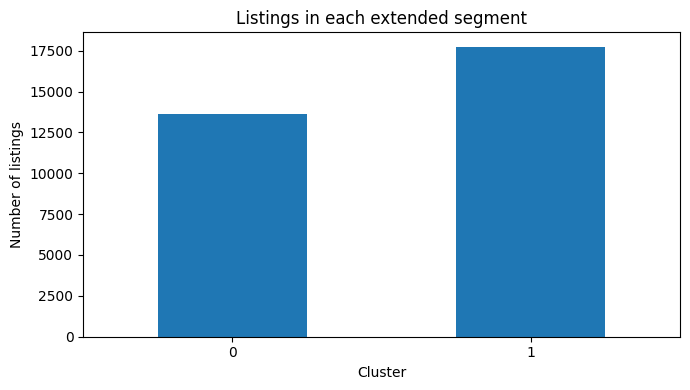

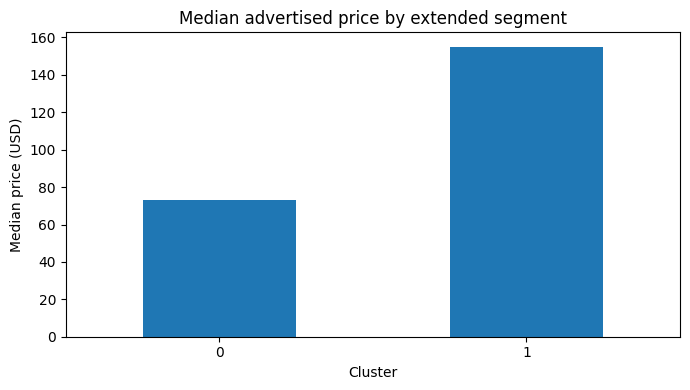

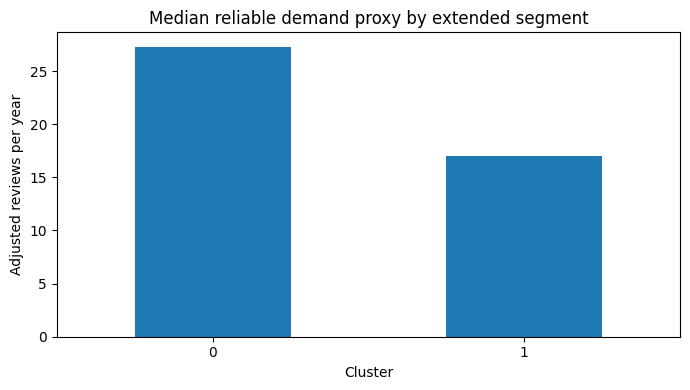

In [14]:
cluster_sizes = profile_df["cluster"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
cluster_sizes.plot(kind="bar", ax=ax)
ax.set_title("Listings in each extended segment")
ax.set_xlabel("Cluster")
ax.set_ylabel("Number of listings")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

if "price" in profile_df.columns:
    median_price = profile_df.groupby("cluster")["price"].median()

    fig, ax = plt.subplots(figsize=(7, 4))
    median_price.plot(kind="bar", ax=ax)
    ax.set_title("Median advertised price by extended segment")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Median price (USD)")
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

if {"demand_rate_year", "demand_reliable"}.issubset(profile_df.columns):
    reliable_demand_plot = profile_df.loc[
        profile_df["demand_reliable"].eq(1)
        & profile_df["demand_rate_year"].notna()
    ]

    if not reliable_demand_plot.empty:
        median_demand = (
            reliable_demand_plot
            .groupby("cluster")["demand_rate_year"]
            .median()
        )

        fig, ax = plt.subplots(figsize=(7, 4))
        median_demand.plot(kind="bar", ax=ax)
        ax.set_title("Median reliable demand proxy by extended segment")
        ax.set_xlabel("Cluster")
        ax.set_ylabel("Adjusted reviews per year")
        ax.tick_params(axis="x", rotation=0)
        plt.tight_layout()
        plt.show()

## 13. Compare baseline and extended segmentation

The comparison focuses on separation, repeatability, cluster size and model complexity. A richer segmentation is only preferable if the additional variables provide a clear improvement rather than adding complexity without stronger structure.

In [15]:
comparison = pd.DataFrame(
    {
        "measure": [
            "Selected k",
            "Silhouette score",
            "Stability ARI",
            "Smallest cluster",
            "Smallest cluster share",
            "Clustering variables",
        ],
        "baseline": [
            int(baseline_selected["k"]),
            baseline_selected["silhouette"],
            baseline_selected["stability_ari"],
            int(baseline_selected["smallest_cluster_n"]),
            baseline_selected["smallest_cluster_share"],
            2,
        ],
        "extended": [
            int(selected_row["k"]),
            selected_row["silhouette"],
            selected_row["stability_ari"],
            int(selected_row["smallest_cluster_n"]),
            selected_row["smallest_cluster_share"],
            4,
        ],
    }
)

display(comparison)

,measure,baseline,extended
0,Selected k,5.000,2.000
1,Silhouette score,0.660,0.406
2,Stability ARI,0.763,0.883
3,Smallest cluster,"2,544.000","13,604.000"
4,Smallest cluster share,0.081,0.434
5,Clustering variables,2.000,4.000


In [16]:
silhouette_change = (
    selected_row["silhouette"] - baseline_selected["silhouette"]
    if pd.notna(selected_row["silhouette"])
    and pd.notna(baseline_selected["silhouette"])
    else np.nan
)

stability_change = (
    selected_row["stability_ari"]
    - baseline_selected["stability_ari"]
)

print("BASELINE VS EXTENDED")
print("--------------------")
print(f"Baseline k: {int(baseline_selected['k'])}")
print(f"Extended k: {SELECTED_K}")

if pd.notna(silhouette_change):
    print(f"Change in silhouette: {silhouette_change:+.3f}")

print(f"Change in stability ARI: {stability_change:+.3f}")
print(
    f"Extended smallest cluster: "
    f"{int(selected_row['smallest_cluster_n']):,} listings"
)

BASELINE VS EXTENDED
--------------------
Baseline k: 5
Extended k: 2
Change in silhouette: -0.254
Change in stability ARI: +0.120
Extended smallest cluster: 13,604 listings


## 14. Segmentation assessment

The extended segmentation should be preferred only when the additional behavioural variables produce a clear improvement in cluster quality and lead to segments that remain easy to interpret.

The baseline remains the reference model because it captures the main structural differences using fewer inputs. The final segmentation choice should therefore consider the evaluation measures together with the observed segment profiles.

In [17]:
print("EXTENDED CLUSTERING SUMMARY")
print("---------------------------")
print(f"Listings clustered: {len(cluster_df):,}")
print(f"Selected k: {SELECTED_K}")
print(
    f"Smallest cluster: "
    f"{cluster_df['cluster'].value_counts().min():,} listings"
)
print(
    f"Largest cluster: "
    f"{cluster_df['cluster'].value_counts().max():,} listings"
)

if pd.notna(selected_row["silhouette"]):
    print(f"Silhouette score: {selected_row['silhouette']:.3f}")
else:
    print("Silhouette score: not available for this solution.")

print(f"Stability ARI: {selected_row['stability_ari']:.3f}")

EXTENDED CLUSTERING SUMMARY
---------------------------
Listings clustered: 31,340
Selected k: 2
Smallest cluster: 13,604 listings
Largest cluster: 17,736 listings
Silhouette score: 0.406
Stability ARI: 0.883


## 15. Save results

The extended labels, evaluation results, profiles, prototypes and baseline comparison are saved for the final segmentation decision and later analysis.

In [18]:
labels_path = OUTPUT_DIR / "extended_cluster_labels.csv"
evaluation_path = OUTPUT_DIR / "extended_cluster_evaluation.csv"
profiles_path = OUTPUT_DIR / "extended_cluster_profiles.csv"
prototypes_path = OUTPUT_DIR / "extended_cluster_prototypes.csv"
comparison_path = OUTPUT_DIR / "baseline_vs_extended_comparison.csv"

model_path = MODEL_DIR / "extended_kprototypes.joblib"
scaler_path = MODEL_DIR / "extended_distance_scaler.joblib"

cluster_df[["id", "cluster"]].to_csv(labels_path, index=False)
results_df.to_csv(evaluation_path, index=False)
profile_summary.reset_index().to_csv(profiles_path, index=False)
prototype_table.to_csv(prototypes_path, index=False)
comparison.to_csv(comparison_path, index=False)

joblib.dump(selected_model, model_path)
joblib.dump(scaler, scaler_path)

print(f"Saved labels: {labels_path}")
print(f"Saved evaluation: {evaluation_path}")
print(f"Saved profiles: {profiles_path}")
print(f"Saved prototypes: {prototypes_path}")
print(f"Saved comparison: {comparison_path}")
print(f"Saved model: {model_path}")
print(f"Saved scaler: {scaler_path}")

Saved labels: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\clustering\extended\extended_cluster_labels.csv
Saved evaluation: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\clustering\extended\extended_cluster_evaluation.csv
Saved profiles: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\clustering\extended\extended_cluster_profiles.csv
Saved prototypes: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\clustering\extended\extended_cluster_prototypes.csv
Saved comparison: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\clustering\extended\baseline_vs_extended_comparison.csv
Saved model: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\models\clustering\extended_kprototypes.joblib
Saved scaler: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\models\clustering\extended_distanc